In [1]:
%pip -q install pycocotools==2.0.11 tqdm
!git clone https://github.com/mdmohsin212/WasteScope.git

Cloning into 'WasteScope'...
remote: Enumerating objects: 411, done.
remote: Counting objects: 100% (411/411), done.
remote: Compressing objects: 100% (223/223), done.
remote: Total 411 (delta 214), reused 345 (delta 154), pack-reused 0 (from 0)
Receiving objects: 100% (411/411), 23.51 MiB | 23.88 MiB/s, done.
Resolving deltas: 100% (214/214), done.


In [2]:
from google.colab import drive
import sys
from pathlib import Path
drive.mount("/content/drive")

REPO_DIR = Path("/content/WasteScope")
sys.path.insert(0, str(REPO_DIR))

Mounted at /content/drive


In [ ]:
import hashlib
import json
import re
import shutil
import struct
from pathlib import PurePosixPath
from zipfile import ZipFile, ZIP_STORED
import pandas as pd
from tqdm.auto import tqdm
from io import BytesIO
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from src.data.boxes import xywhn_to_xyxy
from src.data.annotations import parse_yolo_labels
from src.data.splits import SplitManifest

In [4]:
BASE = Path("/content/drive/MyDrive/WasteScope")
WORK = Path("/content/wastescope_tracking")
PREPARED = BASE / "prepared/tracking"
REPORT = BASE / "reports/tracking/preparation"

for folder in (WORK, PREPARED, REPORT):
    folder.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = (
    BASE / "reports/detection/D1_yolo26n_960/val_960/video_split.json"
)

manifest = SplitManifest.from_file(MANIFEST_PATH)
source_zip = BASE / "raw_archives/tracking_task.zip"
local_zip = WORK / "tracking_task.zip"

if not local_zip.exists() or local_zip.stat().st_size != source_zip.stat().st_size:
    print("Copying tracking ZIP to local storage...", flush=True)
    shutil.copy2(source_zip, local_zip)


with ZipFile(BASE / "raw_archives/detection_task.zip") as archive:
    readme_member = next(
        name for name in archive.namelist()
        if name.lower().endswith("readme.md")
    )
    readme = archive.read(readme_member).decode("utf-8-sig")

Copying tracking ZIP to local storage...


In [5]:
source_classes = {
    int(class_id): name
    for class_id, name in re.findall(
        r"^\s*(\d+):\s*(container_\w+)\s*$",
        readme,
        flags=re.MULTILINE 
    )
}

target_ids = {name: index for index, name in enumerate(manifest.classes)}
class_map = {
    source_id: target_ids.get(name)
    for source_id, name in source_classes.items()
}

display(pd.DataFrame([
    {"Source ID": source_id, "Class": name, "Target ID": class_map[source_id]}
    for source_id, name in source_classes.items()
]))

,Source ID,Class,Target ID
0,0,container_yellow,0.0
1,1,container_green,1.0
2,2,container_default,2.0
3,3,container_blue,3.0
4,4,container_ash,NaN
5,5,container_oil,4.0
6,6,container_battery,5.0
7,7,container_biodegradable,6.0


**frame index and tracking annotations**

In [6]:
frame_rows, annotation_rows = [], []

with ZipFile(local_zip) as archive:
    images = {
        PurePosixPath(name).stem: name
        for name in archive.namelist()
        if name.lower().endswith(".png")
    }
    label_members = {
        PurePosixPath(name).stem: name
        for name in archive.namelist()
        if name.lower().endswith(".txt")
    }

    for stem, image_member in tqdm(sorted(images.items())):
        video, camera, overflow, positive, source_frame = stem.split("_")
        sequence = f"{video}_{camera}"
        split = manifest.split_for(image_member)
        label_member = label_members[stem]
        
        text = archive.read(label_member).decode("utf-8-sig")
        labels = parse_yolo_labels(
            text, class_map=class_map,
            format="tracking", source=label_member
        )
        
        with archive.open(image_member) as image:
            width, height = struct.unpack(">II", image.read(24)[16:24])
        
        frame_rows.append({
            "Split": split,
            "Sequence": sequence,
            "Video": video,
            "Camera": camera,
            "SourceFrame": int(source_frame),
            "Image": PurePosixPath(image_member).name,
            "ImageMember": image_member,
            "LabelMember": label_member,
            "Width": width,
            "Height": height,
            "Objects": len(labels),
            "Excluded": sum(bool(line.strip()) for line in text.splitlines()) - len(labels)
        })
        
        for label in labels:
            xc, yc, w, h = label.xywhn
            annotation_rows.append({
                "Split": split,
                "Sequence": sequence,
                "SourceFrame": int(source_frame),
                "TrackID": label.track_id,
                "ClassID": label.class_id,
                "Class": manifest.classes[label.class_id],
                "Confidence": label.confidence,
                "xc": xc, "yc": yc, "w": w, "h": h
            })

  0%|          | 0/10022 [00:00<?, ?it/s]

In [7]:
frames = pd.DataFrame(frame_rows).sort_values(["Split", "Sequence", "SourceFrame"]).reset_index(drop=True)

frames["Frame"] = frames.groupby("Sequence").cumcount() + 1
frames["GapBefore"] = (frames.groupby("Sequence")["SourceFrame"].diff() > 1).astype(int)

annotations = pd.DataFrame(annotation_rows).merge(
    frames[["Sequence", "SourceFrame", "Frame"]],
    on=["Sequence", "SourceFrame"],
    validate="many_to_one",
).sort_values(["Split", "Sequence", "Frame", "TrackID"])

quality = {
    "duplicate_track_ids_in_frame": int(annotations.duplicated(["Sequence", "Frame", "TrackID"]).sum()),
    "tracks_with_multiple_classes": int(annotations.groupby(["Sequence", "TrackID"])["ClassID"].nunique().gt(1).sum())
}

print("Tracking annotation checks:", quality)

Tracking annotation checks: {'duplicate_track_ids_in_frame': 87, 'tracks_with_multiple_classes': 0}


In [8]:
unique_tracks = annotations.drop_duplicates(["Sequence", "TrackID"])
sequence_summary = frames.groupby("Sequence").agg(
    Split=("Split", "first"),
    Video=("Video", "first"),
    Camera=("Camera", "first"),
    Frames=("Frame", "size"),
    Instances=("Objects", "sum"),
    Excluded=("Excluded", "sum"),
    FrameGaps=("GapBefore", "sum")
)

sequence_summary["Tracks"] = unique_tracks.groupby("Sequence").size().reindex(sequence_summary.index, fill_value=0)

split_summary = sequence_summary.groupby("Split").agg(
    Sequences=("Frames", "size"),
    Frames=("Frames", "sum"),
    Instances=("Instances", "sum"),
    Tracks=("Tracks", "sum"),
    Excluded=("Excluded", "sum"),
    FrameGaps=("FrameGaps", "sum")
).reindex(["train", "val", "test"]).fillna(0).astype(int)

class_summary = pd.DataFrame({
    "Instances": annotations.groupby("Class").size(),
    "Tracks": unique_tracks.groupby("Class").size()
}).reindex(manifest.classes).fillna(0).astype(int)

configuration = {
    "source_archive": "raw_archives/tracking_task.zip",
    "source_class_document": f"raw_archives/detection_task.zip::{readme_member}",
    "source_classes": source_classes,
    "class_map": class_map,
    "classes": list(manifest.classes),
    "manifest_sha256": hashlib.sha256(MANIFEST_PATH.read_bytes()).hexdigest(),
    "sequence": "video_id + camera_id",
    "frame_order": "numeric source frame index",
    "frame_numbering": "1-based within each sequence; SourceFrame preserved",
    "box_format": "normalized xc, yc, width, height",
    "track_id_scope": "sequence",
    "quality": quality
}

frames.to_csv(PREPARED / "frames.csv", index=False)
annotations.to_csv(PREPARED / "annotations.csv", index=False)
shutil.copy2(MANIFEST_PATH, PREPARED / "video_split.json")

(PREPARED / "data_config.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")

sequence_summary.to_csv(REPORT / "sequences.csv")
split_summary.to_csv(REPORT / "split_summary.csv")
class_summary.to_csv(REPORT / "class_summary.csv")

display(split_summary)
display(class_summary)
print("Annotation checks:", quality)
print("Prepared metadata:", PREPARED)
print("Reports:", REPORT)

,Sequences,Frames,Instances,Tracks,Excluded,FrameGaps
Split,,,,,,
train,66,7118,23802,264,196,1
val,13,1480,5700,56,0,0
test,14,1424,4697,54,0,0


,Instances,Tracks
Class,,
container_yellow,5010,51
container_green,5141,55
container_default,15862,182
container_blue,5479,55
container_oil,890,8
container_battery,1294,18
container_biodegradable,523,5


Annotation checks: {'duplicate_track_ids_in_frame': 87, 'tracks_with_multiple_classes': 0}
Prepared metadata: /content/drive/MyDrive/WasteScope/prepared/tracking
Reports: /content/drive/MyDrive/WasteScope/reports/tracking/preparation


**GT IDS**

In [9]:
annotations = pd.read_csv(PREPARED / "annotations.csv", dtype={"Sequence": str})
frames = pd.read_csv(PREPARED / "frames.csv", dtype={"Sequence": str})

keys = ["Sequence", "Frame", "TrackID"]
conflicts = annotations[annotations.duplicated(keys, keep=False)].copy()

issues = conflicts.groupby(["Split", "Sequence", "TrackID"]).agg(
    ConflictingFrames=("Frame", "nunique"),
    FirstFrame=("Frame", "min"),
    LastFrame=("Frame", "max")
)

REVIEW = REPORT / "identity_review"
REVIEW.mkdir(parents=True, exist_ok=True)

conflicts.to_csv(REVIEW / "conflicting_annotations.csv", index=False)
issues.to_csv(REVIEW / "issue_summary.csv")
display(issues)

ConflictingFrames  FirstFrame  LastFrame
Split Sequence TrackID                                          
test  0115_1   44                      82          20        101
val   0075_1   9                        2          59         60
      0103_1   31                       3          22         25

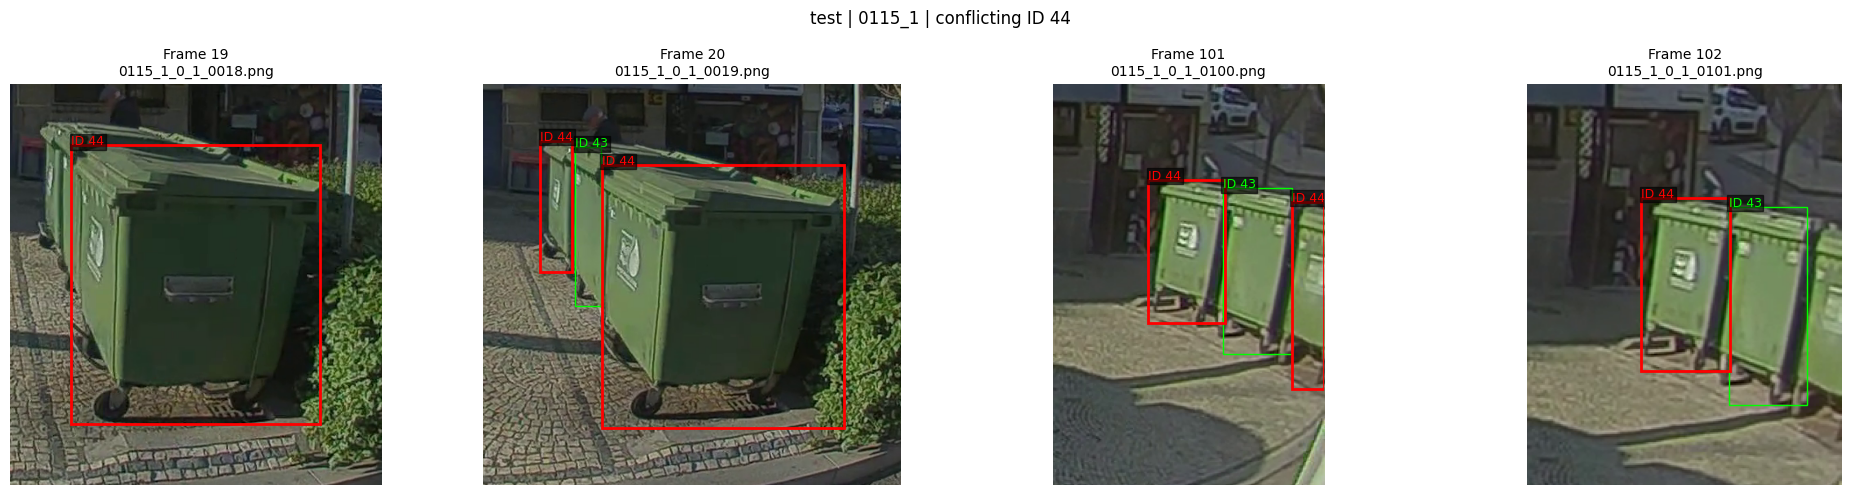

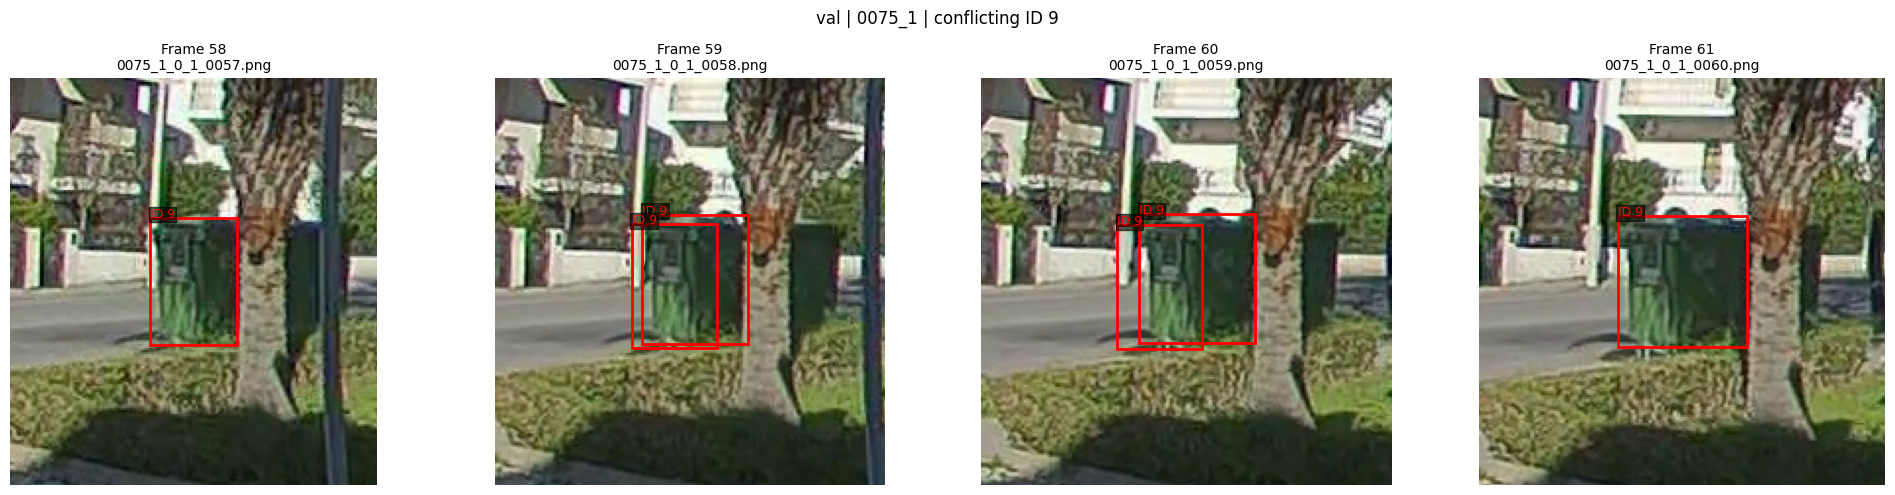

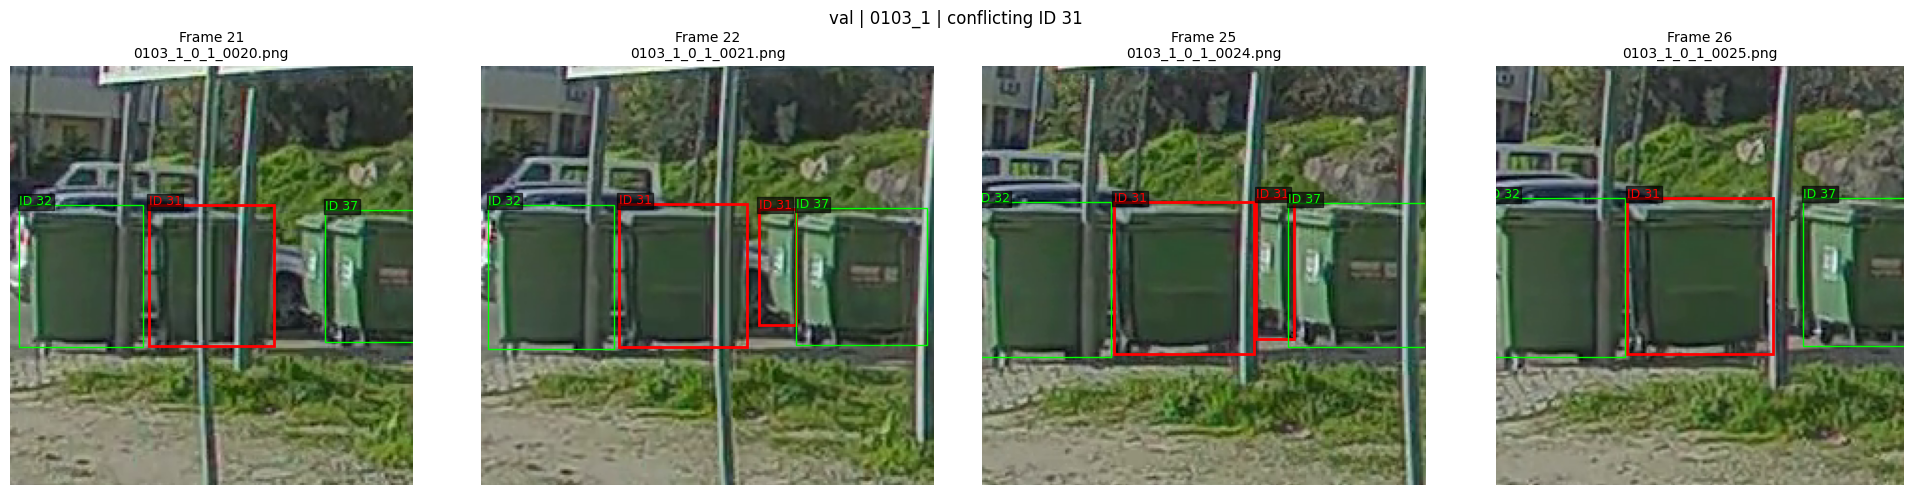

Review saved: /content/drive/MyDrive/WasteScope/reports/tracking/preparation/identity_review


In [10]:
with ZipFile(local_zip) as archive:
    for (split, sequence, track_id), issue in issues.iterrows():
        sequence_frames = frames[frames["Sequence"].eq(sequence)]
        
        first = int(issue["FirstFrame"])
        last = int(issue["LastFrame"])
        maximum = int(sequence_frames["Frame"].max())
        
        selected_frames = sorted({
            max(1, first - 1), first,
            last, min(maximum, last + 1)
        })
        
        fig, axes = plt.subplots(1, len(selected_frames), figsize=(5 * len(selected_frames), 5))
        if len(selected_frames) == 1:
            axes = [axes]

        for ax, frame_number in zip(axes, selected_frames):
            frame = sequence_frames[sequence_frames["Frame"].eq(frame_number)].iloc[0]
            image = Image.open(BytesIO(archive.read(frame["ImageMember"]))).convert("RGB")
            width, height = image.size
            ax.imshow(image)

            labels = annotations[
                annotations["Sequence"].eq(sequence)
                & annotations["Frame"].eq(frame_number)
            ]

            focus = []
            for label in labels.itertuples(index=False):
                box = xywhn_to_xyxy((label.xc, label.yc, label.w, label.h), width, height, clip=True)
                x1, y1, x2, y2 = box
                highlighted = label.TrackID == track_id
                color = "red" if highlighted else "lime"

                if highlighted:
                    focus.append(box)

                ax.add_patch(Rectangle(
                    (x1, y1), x2 - x1, y2 - y1,
                    fill=False, edgecolor=color,
                    linewidth=2 if highlighted else 1,
                ))
                ax.text(
                    x1, y1, f"ID {label.TrackID}",
                    color=color, fontsize=9, clip_on=True,
                    bbox={"facecolor": "black", "alpha": 0.6, "pad": 1},
                )

            if focus:
                margin = 70
                ax.set_xlim(
                    max(0, min(box[0] for box in focus) - margin),
                    min(width, max(box[2] for box in focus) + margin)
                )
                ax.set_ylim(
                    min(height, max(box[3] for box in focus) + margin),
                    max(0, min(box[1] for box in focus) - margin)
                )

            ax.set_title(f"Frame {frame_number}\n{frame['Image']}", fontsize=10)
            ax.axis("off")

        fig.suptitle(f"{split} | {sequence} | conflicting ID {track_id}")
        fig.tight_layout()
        fig.savefig(REVIEW / f"{sequence}_id{track_id}.jpg", dpi=170, bbox_inches="tight")
        plt.show()
        plt.close(fig)

print("Review saved:", REVIEW)

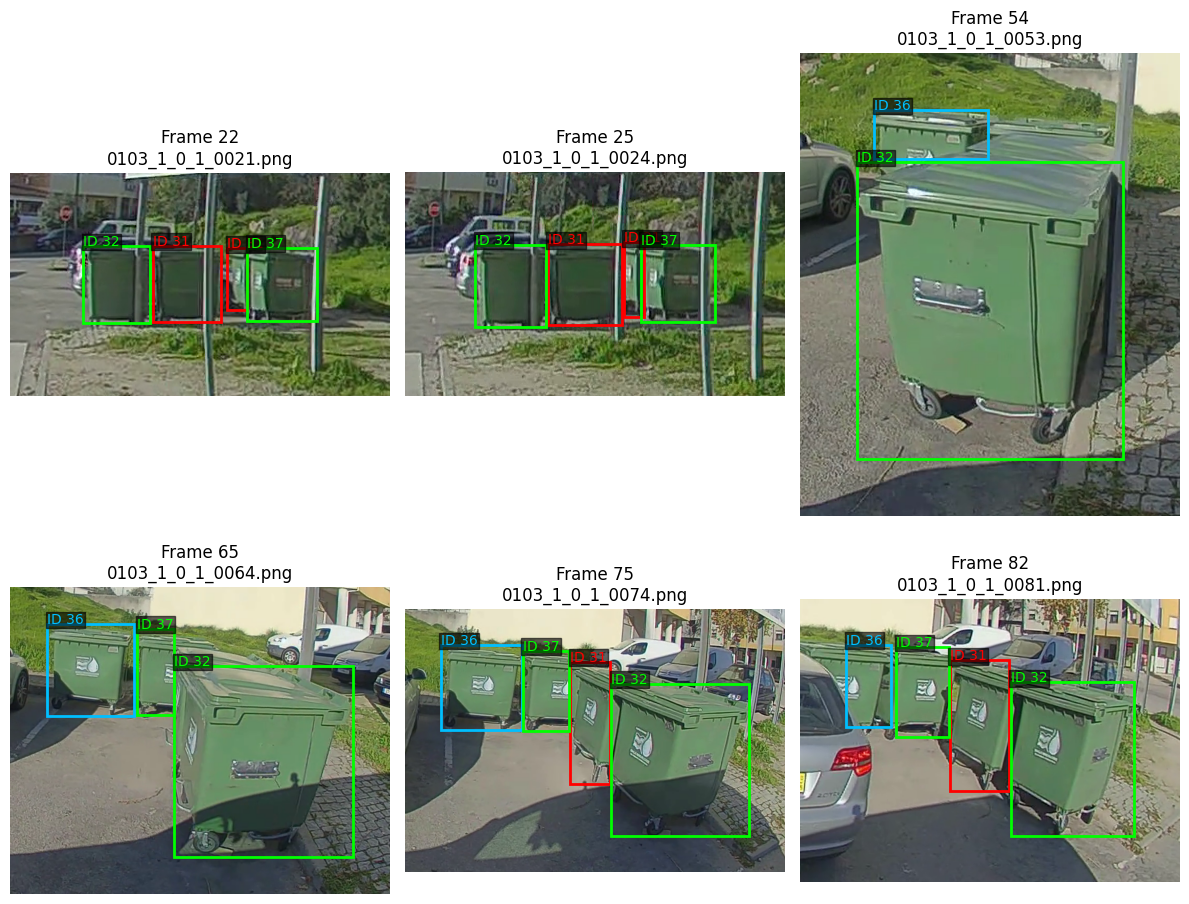

In [11]:
sequence = "0103_1"
selected_frames = [22, 25, 54, 65, 75, 82]
fig, axes = plt.subplots(2, 3, figsize=(12, 10))

with ZipFile(local_zip) as archive:
    for ax, frame_number in zip(axes.flat, selected_frames):
        frame = frames[
            frames["Sequence"].eq(sequence)
            & frames["Frame"].eq(frame_number)
        ].iloc[0]
        
        image = Image.open(
            BytesIO(archive.read(frame["ImageMember"]))
        ).convert("RGB")
        width, heigth = image.size
        ax.imshow(image)
        
        labels = annotations[
            annotations["Sequence"].eq(sequence)
            & annotations["Frame"].eq(frame_number)
        ]
        
        regions = []
        for label in labels.itertuples(index=False):
            x1, y1, x2, y2 = xywhn_to_xyxy(
                (label.xc, label.yc, label.w, label.h),
                width, height, clip=True
            )
            regions.append((x1, y1, x2, y2))
            color = {31: "red", 36: "deepskyblue"}.get(
                label.TrackID, "lime"
            )

            ax.add_patch(Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor=color, linewidth=2
            ))
            ax.text(
                x1, y1, f"ID {label.TrackID}",
                color=color, fontsize=10, clip_on=True,
                bbox={"facecolor": "black", "alpha": 0.6, "pad": 1}
            )

        ax.set_xlim(
            max(0, min(box[0] for box in regions) - 70),
            min(width, max(box[2] for box in regions) + 70)
        )
        ax.set_ylim(
            min(height, max(box[3] for box in regions) + 70),
            max(0, min(box[1] for box in regions) - 70)
        )
        ax.set_title(f"Frame {frame_number}\n{frame['Image']}")
        ax.axis("off")

fig.tight_layout()
fig.savefig(REVIEW / "0103_1_id31_id36_review.jpg", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

In [12]:
raw = pd.read_csv(PREPARED / "annotations.csv", dtype={"Sequence": str})
corrected = raw.copy()
box_columns = ["xc", "yc", "w", "h"]

reference = raw.query(
    "Sequence == '0075_1' and TrackID == 9 and Frame == 58"
)[box_columns].iloc[0]

candidates = raw.query("Sequence == '0075_1' and TrackID == 9 and Frame in [59, 60]")

stale = candidates.index[
    candidates[box_columns].eq(reference).all(axis=1)
]

rear_bin = raw.query(
    "Sequence == '0103_1' and TrackID == 31 and Frame in [22, 24, 25]"
).groupby("Frame")["xc"].idxmax()

second_bin = raw.query(
    "Sequence == '0115_1' and TrackID == 44 and Frame >= 20"
).groupby("Frame")["xc"].idxmin()

new_id = int(raw.loc[raw["Sequence"].eq("0115_1"), "TrackID"].max()) + 1

operations = [
    (stale, None, "Remove stale duplicate box"),
    (rear_bin, 36, "Restore rear-bin identity after visual review"),
    (second_bin, new_id, "Separate second bin from ID 44")
]

In [13]:
logs = []
for indices, target_id, reason in operations:
    changes = raw.loc[indices].rename(columns={"TrackID": "OldTrackID"}).copy()
    changes["NewTrackID"] = pd.array([target_id] * len(changes), dtype="Int64")
    changes["Reason"] = reason
    logs.append(changes)

    if target_id is None:
        corrected = corrected.drop(index=indices)
    else:
        corrected.loc[indices, "TrackID"] = target_id

quality = {
    "duplicate_track_ids_in_frame": int(corrected.duplicated(["Sequence", "Frame", "TrackID"]).sum()),
    "tracks_with_multiple_classes": int(corrected.groupby(["Sequence", "TrackID"])["ClassID"].nunique().gt(1).sum())
}

frames_corrected = pd.read_csv(PREPARED / "frames.csv", dtype={"Sequence": str, "Video": str, "Camera": str}).drop(columns="Objects").merge(
    corrected.groupby(["Sequence", "Frame"]).size().rename("Objects").reset_index(),
    on=["Sequence", "Frame"], how="left"
)

frames_corrected["Objects"] = frames_corrected["Objects"].fillna(0).astype(int)
corrected.to_csv(PREPARED / "annotations_corrected.csv", index=False)
frames_corrected.to_csv(PREPARED / "frames_corrected.csv", index=False)
pd.concat(logs, ignore_index=True).to_csv(PREPARED / "annotation_corrections.csv", index=False)

config = json.loads((PREPARED / "data_config.json").read_text())
config.setdefault("raw_quality", config["quality"])
config.update(
    annotations_file="annotations_corrected.csv",
    frames_file="frames_corrected.csv",
    corrections_file="annotation_corrections.csv",
    quality=quality
)

(PREPARED / "data_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
summary = corrected.groupby("Split").agg(Instances=("TrackID", "size"))
summary["Tracks"] = corrected.drop_duplicates(["Sequence", "TrackID"]).groupby("Split").size()
summary = summary.reindex(["train", "val", "test"])
summary.to_csv(REPORT / "split_summary_corrected.csv")

display(summary)
print("Annotation checks:", quality)
print("Second bin's new ID:", new_id)

,Instances,Tracks
Split,,
train,23802,264
val,5698,56
test,4697,55


Annotation checks: {'duplicate_track_ids_in_frame': 0, 'tracks_with_multiple_classes': 0}
Second bin's new ID: 54


In [ ]:
val_frames = frames_corrected[frames_corrected["Split"].eq("val")]
temporary = PREPARED / "val.zip.part"

with ZipFile(local_zip) as source, ZipFile(temporary, "w", ZIP_STORED) as target:
    for member in tqdm(val_frames["ImageMember"], desc="Saving tracking val.zip"):
        target.writestr(member, source.read(member))

temporary.replace(PREPARED / "val.zip")
print("Saved:", PREPARED / "val.zip")

Saving tracking val.zip:   0%|          | 0/1480 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/WasteScope/prepared/tracking/val.zip
